# Medical Image Classification with PyTorch

## Objective
Build a reproducible baseline for medical image classification using a public chest X-ray dataset.

## Workflow
- Dataset inspection and class distribution
- Train, validation, and test separation
- Image preprocessing and data loaders
- Baseline convolutional neural network
- Training and validation
- Evaluation using clinically relevant classification metrics
- Explainability with Grad-CAM in a later experiment

## Scope and Limitations
This is an educational research project, not a clinical diagnostic system. Dataset limitations, class imbalance, data leakage, and generalization must be considered when interpreting results.

## 1. Dataset Loading and Inspection

We use PneumoniaMNIST, a binary classification dataset derived from chest X-ray images.

The official training, validation, and test splits will be kept separate. First, we inspect the dataset size, image dimensions, class distribution, and sample images before building a model.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import medmnist
from medmnist import INFO

# Select the dataset
data_flag = "pneumoniamnist"
info = INFO[data_flag]
DataClass = getattr(medmnist, info["python_class"])

# Download official splits
train_dataset = DataClass(split="train", download=True)
val_dataset = DataClass(split="val", download=True)
test_dataset = DataClass(split="test", download=True)

datasets = {
    "Train": train_dataset,
    "Validation": val_dataset,
    "Test": test_dataset,
}

print("Dataset:", data_flag)
print("Classes:", info["label"])

for split_name, dataset in datasets.items():
    print(
        f"{split_name}: "
        f"{len(dataset)} images | "
        f"Image shape: {dataset.imgs.shape} | "
        f"Labels shape: {dataset.labels.shape}"
    )

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 4.17M/4.17M [00:02<00:00, 1.79MB/s]

Dataset: pneumoniamnist
Classes: {'0': 'normal', '1': 'pneumonia'}
Train: 4708 images | Image shape: (4708, 28, 28) | Labels shape: (4708, 1)
Validation: 524 images | Image shape: (524, 28, 28) | Labels shape: (524, 1)
Test: 624 images | Image shape: (624, 28, 28) | Labels shape: (624, 1)


In [2]:
for split_name, dataset in datasets.items():
    labels, counts = np.unique(
        dataset.labels.reshape(-1),
        return_counts=True,
    )

    print(f"\n{split_name} class distribution:")

    for label, count in zip(labels, counts):
        class_name = info["label"][str(int(label))]
        percentage = 100 * count / len(dataset)

        print(
            f"  {class_name}: {count} "
            f"({percentage:.1f}%)"
        )


Train class distribution:
  normal: 1214 (25.8%)
  pneumonia: 3494 (74.2%)

Validation class distribution:
  normal: 135 (25.8%)
  pneumonia: 389 (74.2%)

Test class distribution:
  normal: 234 (37.5%)
  pneumonia: 390 (62.5%)


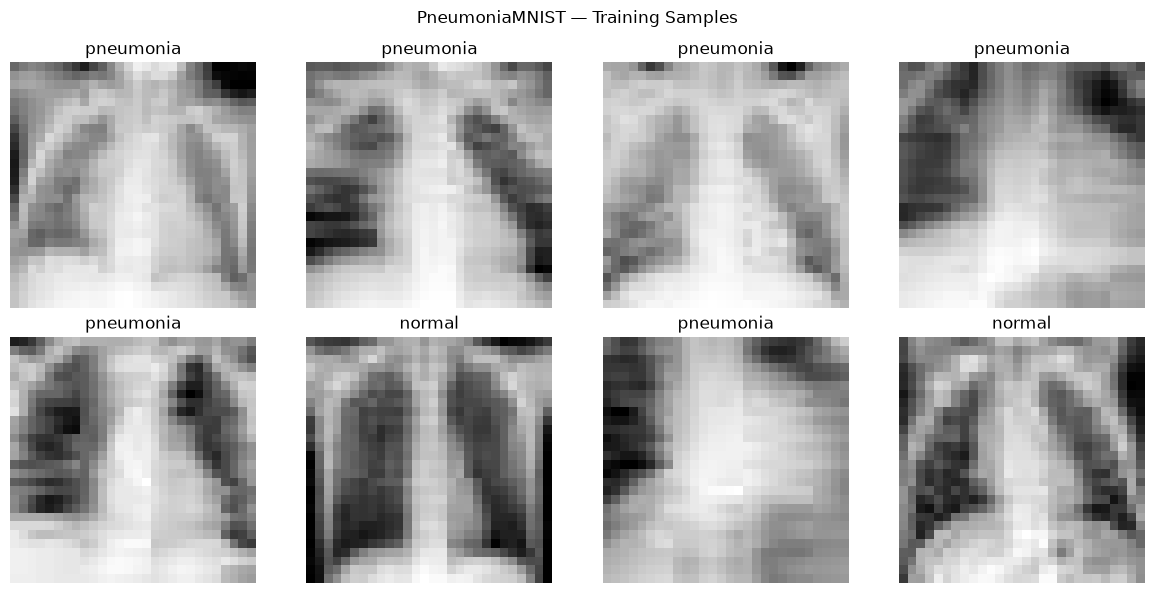

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    label_id = int(np.asarray(label).item())
    class_name = info["label"][str(label_id)]

    ax.imshow(np.asarray(image), cmap="gray")
    ax.set_title(class_name)
    ax.axis("off")

plt.suptitle("PneumoniaMNIST — Training Samples")
plt.tight_layout()
plt.show()

## 2. Data Preprocessing and DataLoaders

We convert images to PyTorch tensors and organize them into batches.

The official training, validation, and test splits remain separate. The test set will not be used for model selection or training.

Images are grayscale, so the model will use one input channel.

In [4]:
import torch
from torch.utils.data import DataLoader
from torchvision import transforms
from medmnist import INFO
import medmnist

data_flag = "pneumoniamnist"
info = INFO[data_flag]
DataClass = getattr(medmnist, info["python_class"])

# Convert images to tensors with pixel values in [0, 1]
transform = transforms.ToTensor()

train_dataset = DataClass(
    split="train",
    transform=transform,
    download=True,
)

val_dataset = DataClass(
    split="val",
    transform=transform,
    download=True,
)

test_dataset = DataClass(
    split="test",
    transform=transform,
    download=True,
)

print("Classes:", info["label"])
print("Image tensor shape:", train_dataset[0][0].shape)
print("Label:", train_dataset[0][1])

Classes: {'0': 'normal', '1': 'pneumonia'}
Image tensor shape: torch.Size([1, 28, 28])
Label: [1]


In [5]:
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
)

images, labels = next(iter(train_loader))

print("Batch images:", images.shape)
print("Batch labels:", labels.shape)
print("Image value range:", images.min().item(), images.max().item())
print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))
print("Number of test batches:", len(test_loader))

Batch images: torch.Size([64, 1, 28, 28])
Batch labels: torch.Size([64, 1])
Image value range: 0.0 0.9686274528503418
Number of training batches: 74
Number of validation batches: 9
Number of test batches: 10


## 3. Baseline Convolutional Neural Network

We build a small CNN for binary classification of grayscale chest X-ray images.

The model uses convolutional layers to learn spatial features, pooling to reduce spatial dimensions, and a fully connected layer to produce one logit for binary classification.

The model is an educational baseline and is not intended for clinical use.

In [6]:
import torch
import torch.nn as nn

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

class PneumoniaCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = PneumoniaCNN().to(device)

print(model)
print("\nDevice:", device)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad),
)

PneumoniaCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)

Device: mps
Trainable parameters: 105281


In [7]:
images, labels = next(iter(train_loader))

images = images.to(device)
outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Output device:", outputs.device)

Input shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 1])
Output device: mps:0


## 4. Model Training

We train the CNN using binary cross-entropy with logits and the Adam optimizer.

At each epoch, we update model parameters using the training set and evaluate the loss on the validation set. The test set remains untouched until final evaluation.

We monitor sensitivity and specificity in addition to accuracy because the dataset has an imbalanced class distribution.

In [8]:
import numpy as np
import torch

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 10
history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_sensitivity": [],
    "val_specificity": [],
}

for epoch in range(epochs):
    # Training
    model.train()
    train_loss_sum = 0.0
    train_samples = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device).float()

        optimizer.zero_grad()

        logits = model(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        batch_size_actual = images.size(0)
        train_loss_sum += loss.item() * batch_size_actual
        train_samples += batch_size_actual

    train_loss = train_loss_sum / train_samples

    # Validation
    model.eval()
    val_loss_sum = 0.0
    val_samples = 0
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device).float()

            logits = model(images)
            loss = criterion(logits, labels)

            batch_size_actual = images.size(0)
            val_loss_sum += loss.item() * batch_size_actual
            val_samples += batch_size_actual

            probabilities = torch.sigmoid(logits)
            predictions = (probabilities >= 0.5).long()

            all_predictions.extend(predictions.cpu().numpy().ravel())
            all_labels.extend(labels.cpu().numpy().astype(int).ravel())

    val_loss = val_loss_sum / val_samples

    y_true = np.asarray(all_labels)
    y_pred = np.asarray(all_predictions)

    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))

    accuracy = (tp + tn) / len(y_true)
    sensitivity = tp / (tp + fn) if (tp + fn) else 0.0
    specificity = tn / (tn + fp) if (tn + fp) else 0.0

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(accuracy)
    history["val_sensitivity"].append(sensitivity)
    history["val_specificity"].append(specificity)

    print(
        f"Epoch {epoch + 1:02d}/{epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Accuracy: {accuracy:.3f} | "
        f"Sensitivity: {sensitivity:.3f} | "
        f"Specificity: {specificity:.3f}"
    )

Epoch 01/10 | Train loss: 0.5193 | Val loss: 0.3984 | Accuracy: 0.742 | Sensitivity: 1.000 | Specificity: 0.000
Epoch 02/10 | Train loss: 0.3117 | Val loss: 0.2753 | Accuracy: 0.914 | Sensitivity: 0.987 | Specificity: 0.704
Epoch 03/10 | Train loss: 0.2616 | Val loss: 0.2327 | Accuracy: 0.948 | Sensitivity: 0.979 | Specificity: 0.859
Epoch 04/10 | Train loss: 0.1700 | Val loss: 0.1376 | Accuracy: 0.948 | Sensitivity: 0.961 | Specificity: 0.911
Epoch 05/10 | Train loss: 0.1347 | Val loss: 0.1257 | Accuracy: 0.950 | Sensitivity: 0.985 | Specificity: 0.852
Epoch 06/10 | Train loss: 0.1239 | Val loss: 0.1185 | Accuracy: 0.956 | Sensitivity: 0.985 | Specificity: 0.874
Epoch 07/10 | Train loss: 0.1140 | Val loss: 0.1118 | Accuracy: 0.950 | Sensitivity: 0.974 | Specificity: 0.881
Epoch 08/10 | Train loss: 0.1214 | Val loss: 0.1164 | Accuracy: 0.956 | Sensitivity: 0.987 | Specificity: 0.867
Epoch 09/10 | Train loss: 0.1055 | Val loss: 0.1059 | Accuracy: 0.964 | Sensitivity: 0.974 | Specificity

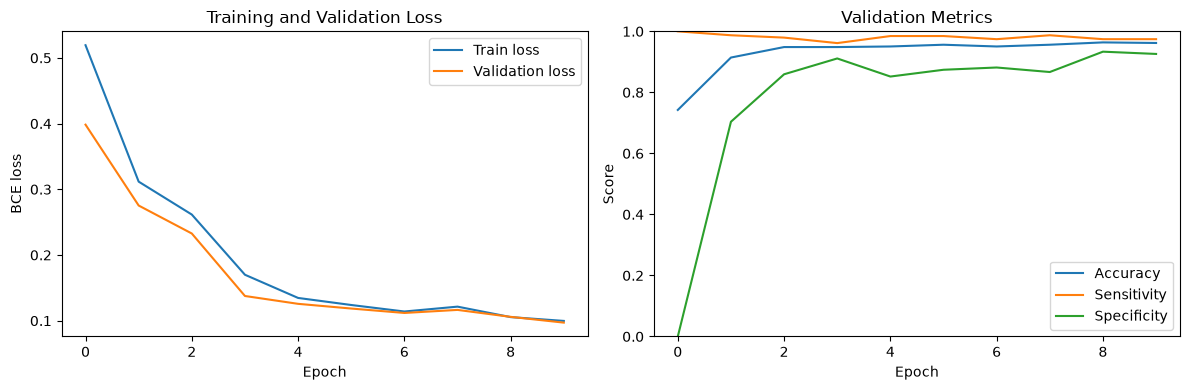

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["train_loss"], label="Train loss")
axes[0].plot(history["val_loss"], label="Validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE loss")
axes[0].set_title("Training and Validation Loss")
axes[0].legend()

axes[1].plot(history["val_accuracy"], label="Accuracy")
axes[1].plot(history["val_sensitivity"], label="Sensitivity")
axes[1].plot(history["val_specificity"], label="Specificity")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_title("Validation Metrics")
axes[1].legend()
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

## 5. Final Evaluation on the Test Set

We evaluate the trained model on the held-out test split.

The test set is not used for training or model selection. We report accuracy, precision, sensitivity, specificity, F1-score, and a confusion matrix to better understand classification errors.

These results describe performance on this dataset only and do not establish clinical validity or generalization to other hospitals or populations.

In [10]:
import numpy as np
import torch
import matplotlib.pyplot as plt

model.eval()

all_labels = []
all_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        logits = model(images)
        probabilities = torch.sigmoid(logits)

        all_probabilities.extend(
            probabilities.cpu().numpy().ravel()
        )
        all_labels.extend(
            labels.cpu().numpy().astype(int).ravel()
        )

y_true = np.asarray(all_labels)
y_prob = np.asarray(all_probabilities)
y_pred = (y_prob >= 0.5).astype(int)

# Positive class = pneumonia (1)
tn = np.sum((y_true == 0) & (y_pred == 0))
fp = np.sum((y_true == 0) & (y_pred == 1))
fn = np.sum((y_true == 1) & (y_pred == 0))
tp = np.sum((y_true == 1) & (y_pred == 1))

accuracy = (tp + tn) / len(y_true)
precision = tp / (tp + fp) if (tp + fp) else 0.0
sensitivity = tp / (tp + fn) if (tp + fn) else 0.0
specificity = tn / (tn + fp) if (tn + fp) else 0.0
f1 = (
    2 * precision * sensitivity / (precision + sensitivity)
    if (precision + sensitivity) else 0.0
)
balanced_accuracy = (sensitivity + specificity) / 2

print("TEST RESULTS")
print(f"Test images:       {len(y_true)}")
print(f"Accuracy:          {accuracy:.4f}")
print(f"Precision:         {precision:.4f}")
print(f"Sensitivity:       {sensitivity:.4f}")
print(f"Specificity:       {specificity:.4f}")
print(f"F1-score:          {f1:.4f}")
print(f"Balanced accuracy: {balanced_accuracy:.4f}")

print("\nConfusion matrix counts:")
print(f"True negatives:  {tn}")
print(f"False positives: {fp}")
print(f"False negatives: {fn}")
print(f"True positives:  {tp}")

TEST RESULTS
Test images:       624
Accuracy:          0.8542
Precision:         0.8174
Sensitivity:       0.9872
Specificity:       0.6325
F1-score:          0.8943
Balanced accuracy: 0.8098

Confusion matrix counts:
True negatives:  148
False positives: 86
False negatives: 5
True positives:  385


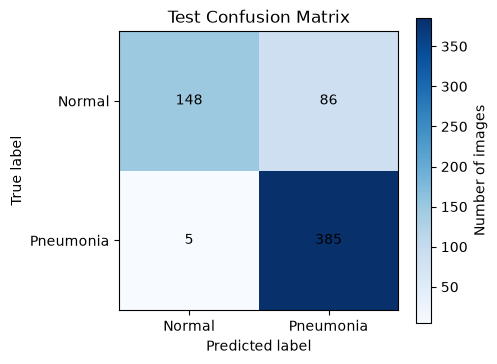

In [11]:
confusion_matrix = np.array([
    [tn, fp],
    [fn, tp],
])

fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(confusion_matrix, cmap="Blues")

ax.set_xticks([0, 1], labels=["Normal", "Pneumonia"])
ax.set_yticks([0, 1], labels=["Normal", "Pneumonia"])
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Test Confusion Matrix")

for i in range(2):
    for j in range(2):
        ax.text(
            j, i, str(confusion_matrix[i, j]),
            ha="center", va="center",
            color="black",
        )

fig.colorbar(image, ax=ax, label="Number of images")
plt.tight_layout()
plt.show()

## 6. Saving the Baseline Model

We save the trained model parameters and basic metadata to support reproducibility.

This checkpoint represents the baseline trained for 10 epochs. It has not been clinically validated and should not be used for diagnosis.

In [12]:
from pathlib import Path
import torch

models_dir = Path("models")
models_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = models_dir / "pneumoniamnist_cnn_baseline.pth"

checkpoint = {
    "model_state_dict": model.cpu().state_dict(),
    "model_name": "PneumoniaCNN",
    "dataset": "PneumoniaMNIST",
    "input_shape": [1, 28, 28],
    "class_mapping": {
        "0": "normal",
        "1": "pneumonia",
    },
    "threshold": 0.5,
    "epochs": 10,
}

torch.save(checkpoint, checkpoint_path)

print("Saved to:", checkpoint_path)
print("File size (KB):", round(checkpoint_path.stat().st_size / 1024, 2))

# Move the model back to the selected device
model.to(device)

Saved to: models/pneumoniamnist_cnn_baseline.pth
File size (KB): 415.6


PneumoniaCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)

### Baseline Results and Limitations

**Dataset:** PneumoniaMNIST  
**Architecture:** Two convolutional blocks and a fully connected binary classifier  
**Training:** 10 epochs, Adam optimizer, learning rate 0.001  
**Loss:** BCEWithLogitsLoss  
**Decision threshold:** 0.5

**Test metrics**
- Accuracy: 85.42%
- Precision: 81.74%
- Sensitivity: 98.72%
- Specificity: 63.25%
- F1-score: 89.43%
- Balanced accuracy: 80.98%

**Confusion matrix**
- True negatives: 148
- False positives: 86
- False negatives: 5
- True positives: 385

**Interpretation**

The model achieved high sensitivity but substantially lower specificity on the held-out test set. It detected most pneumonia-positive images but misclassified a considerable number of normal images as pneumonia. The difference between validation and test performance warrants further investigation.

**Limitations**

This is a small educational baseline using low-resolution images. The results are dataset-specific and do not establish clinical validity, robustness, or generalization to other populations or institutions.

## 7. Explainability with Grad-CAM

Grad-CAM (Gradient-weighted Class Activation Mapping) uses gradients flowing into a convolutional layer to produce a coarse localization map for a target class.

In this experiment, we visualize regions that contribute to the model's pneumonia score and compare the heatmaps with the model's predictions.

Grad-CAM is an interpretability aid, not proof of clinical reasoning or diagnostic validity.

In [13]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt


def generate_gradcam(model, image_tensor, target_class, device):
    """
    Generate a Grad-CAM heatmap for a binary classification target.

    Args:
        model: trained PneumoniaCNN
        image_tensor: image tensor with shape [1, 28, 28]
        target_class: 0 (normal) or 1 (pneumonia)
        device: torch device

    Returns:
        heatmap: normalized NumPy array with shape [28, 28]
    """
    model.eval()
    model.zero_grad(set_to_none=True)

    image_tensor = image_tensor.unsqueeze(0).to(device)

    # Forward through convolutional layers
    activations = model.features(image_tensor)
    activations.retain_grad()

    # Forward through classifier
    logits = model.classifier(activations)

    # For class 1, use the logit; for class 0, use its negative
    score = logits[0, 0] if target_class == 1 else -logits[0, 0]
    score.backward()

    # Average gradients spatially to obtain channel weights
    gradients = activations.grad
    weights = gradients.mean(dim=(2, 3), keepdim=True)

    # Weighted combination of feature maps
    cam = torch.sum(weights * activations, dim=1, keepdim=True)
    cam = F.relu(cam)

    # Resize heatmap to the original image dimensions
    cam = F.interpolate(
        cam,
        size=image_tensor.shape[-2:],
        mode="bilinear",
        align_corners=False,
    )

    cam = cam[0, 0]
    cam_min = cam.min()
    cam_max = cam.max()

    if (cam_max - cam_min).item() > 1e-8:
        cam = (cam - cam_min) / (cam_max - cam_min)
    else:
        cam = torch.zeros_like(cam)

    return cam.detach().cpu().numpy()

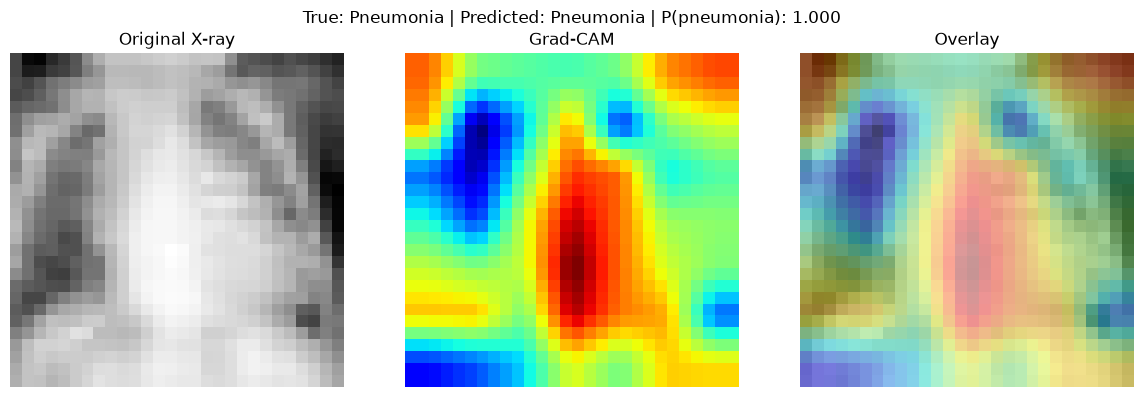

In [14]:
# Select the first test image
sample_index = 0
image_tensor, label = test_dataset[sample_index]

model.eval()

with torch.no_grad():
    logits = model(image_tensor.unsqueeze(0).to(device))
    probability = torch.sigmoid(logits).item()

predicted_class = int(probability >= 0.5)
true_class = int(np.asarray(label).item())

heatmap = generate_gradcam(
    model=model,
    image_tensor=image_tensor,
    target_class=predicted_class,
    device=device,
)

image_np = image_tensor.squeeze().numpy()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(image_np, cmap="gray")
axes[0].set_title("Original X-ray")

axes[1].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("Grad-CAM")

axes[2].imshow(image_np, cmap="gray")
axes[2].imshow(heatmap, cmap="jet", alpha=0.4, vmin=0, vmax=1)
axes[2].set_title("Overlay")

for ax in axes:
    ax.axis("off")

true_name = "Pneumonia" if true_class == 1 else "Normal"
pred_name = "Pneumonia" if predicted_class == 1 else "Normal"

fig.suptitle(
    f"True: {true_name} | Predicted: {pred_name} | "
    f"P(pneumonia): {probability:.3f}"
)
plt.tight_layout()
plt.show()

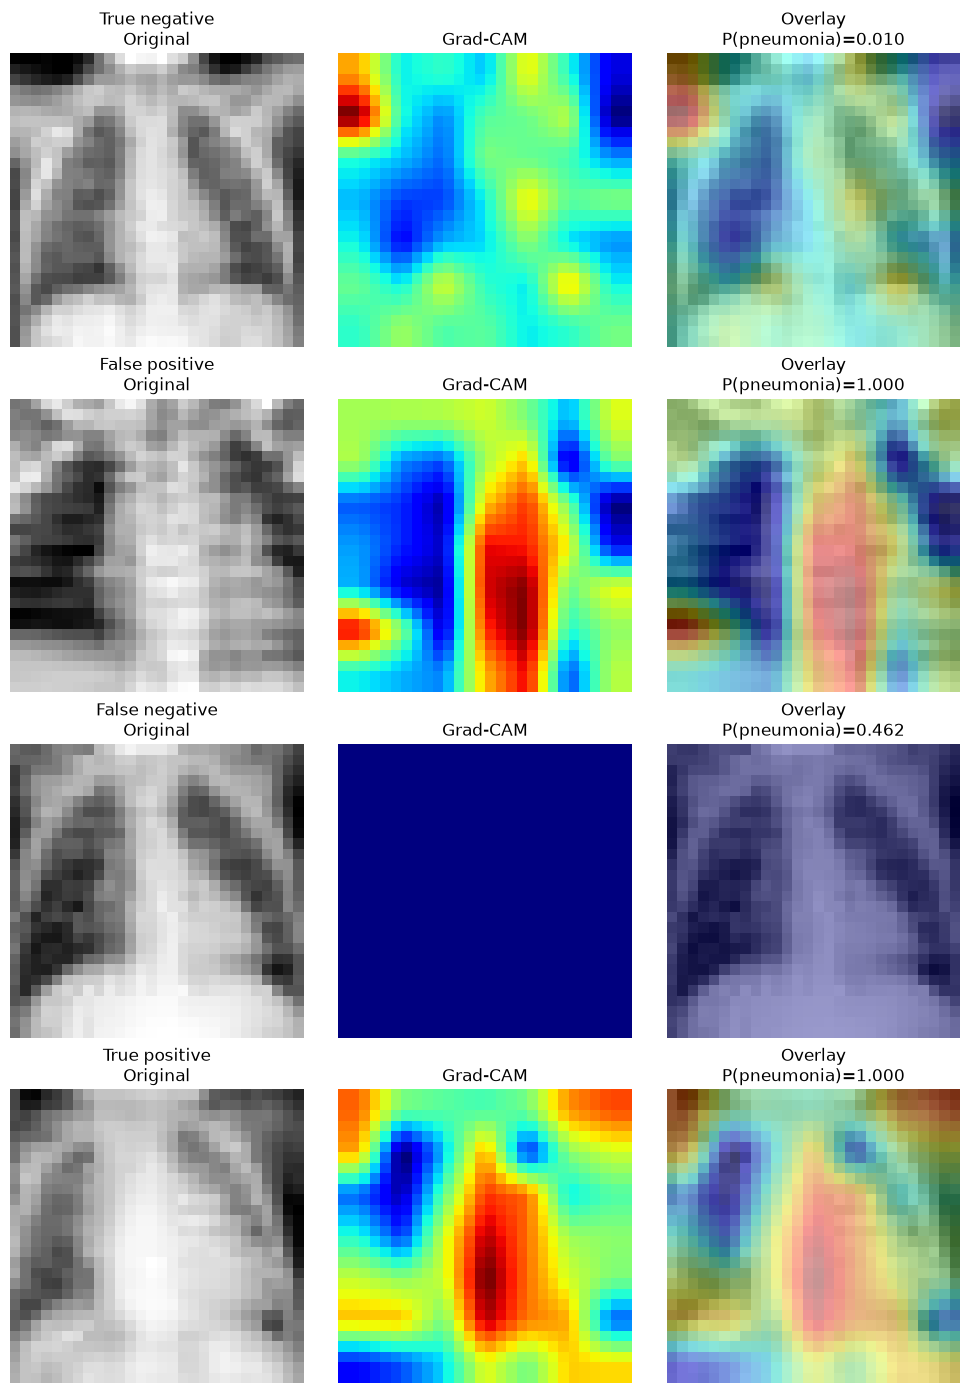

In [15]:
# Find one example of each available outcome
cases = {
    "True negative": np.where((y_true == 0) & (y_pred == 0))[0],
    "False positive": np.where((y_true == 0) & (y_pred == 1))[0],
    "False negative": np.where((y_true == 1) & (y_pred == 0))[0],
    "True positive": np.where((y_true == 1) & (y_pred == 1))[0],
}

selected_cases = [
    (name, int(indices[0]))
    for name, indices in cases.items()
    if len(indices) > 0
]

fig, axes = plt.subplots(
    len(selected_cases), 3,
    figsize=(10, 3.5 * len(selected_cases)),
    squeeze=False,
)

for row, (case_name, index) in enumerate(selected_cases):
    image_tensor, label = test_dataset[index]

    true_class = int(np.asarray(label).item())
    predicted_class = int(y_pred[index])
    probability = float(y_prob[index])

    heatmap = generate_gradcam(
        model,
        image_tensor,
        predicted_class,
        device,
    )

    image_np = image_tensor.squeeze().numpy()

    axes[row, 0].imshow(image_np, cmap="gray")
    axes[row, 0].set_title(f"{case_name}\nOriginal")

    axes[row, 1].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
    axes[row, 1].set_title("Grad-CAM")

    axes[row, 2].imshow(image_np, cmap="gray")
    axes[row, 2].imshow(
        heatmap, cmap="jet", alpha=0.4, vmin=0, vmax=1
    )
    axes[row, 2].set_title(
        f"Overlay\nP(pneumonia)={probability:.3f}"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

### 7.1. Comparing Grad-CAM Across Both Classes

For binary classification, we compare Grad-CAM maps for the normal and pneumonia targets on selected misclassified examples.

This helps inspect how the model's class-specific gradients differ. The maps remain qualitative explanations and must not be interpreted as lesion segmentation or clinical evidence.

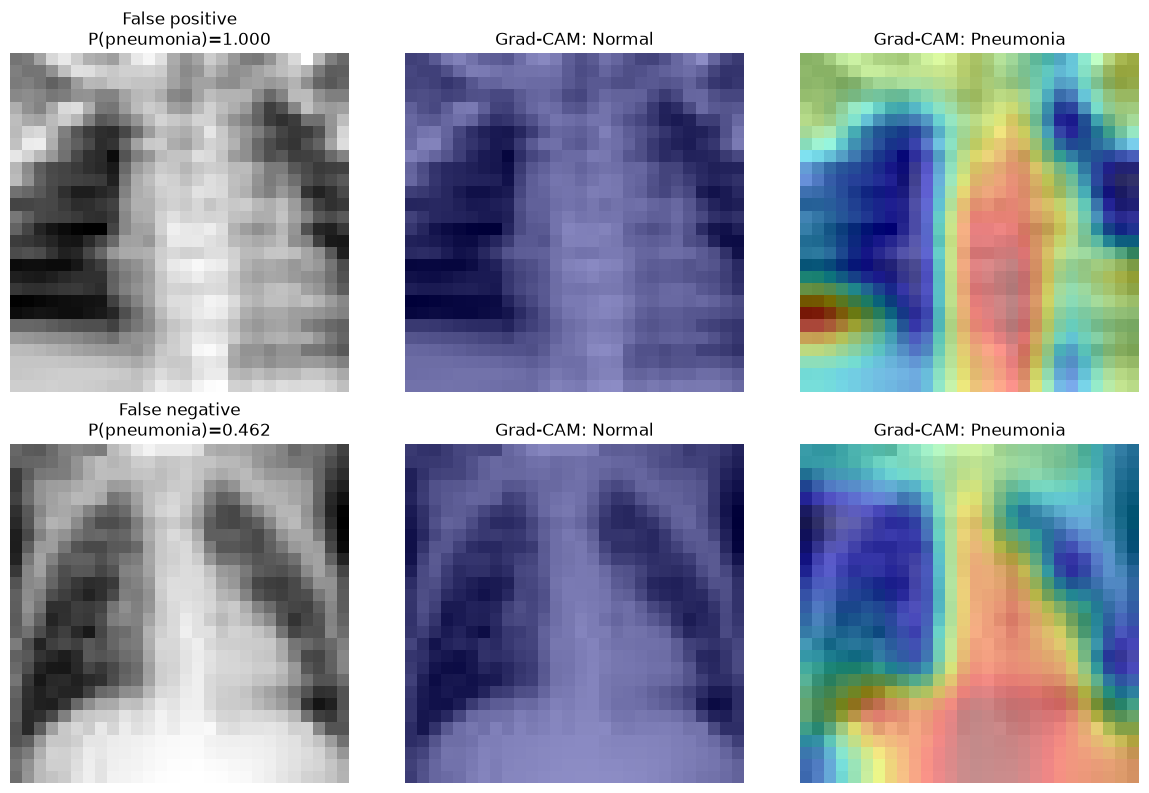

In [17]:
# Select one false positive and one false negative
error_cases = {
    "False positive": np.where((y_true == 0) & (y_pred == 1))[0],
    "False negative": np.where((y_true == 1) & (y_pred == 0))[0],
}

selected_errors = [
    (name, int(indices[0]))
    for name, indices in error_cases.items()
    if len(indices) > 0
]


fig, axes = plt.subplots(
    len(selected_errors), 3,
    figsize=(12, 4 * len(selected_errors)),
    squeeze=False,
)

for row, (case_name, index) in enumerate(selected_errors):
    image_tensor, label = test_dataset[index]
    image_np = image_tensor.squeeze().numpy()

    cam_normal = generate_gradcam(
        model, image_tensor, target_class=0, device=device
    )
    cam_pneumonia = generate_gradcam(
        model, image_tensor, target_class=1, device=device
    )

    probability = float(y_prob[index])

    # Original image: display individual pixels clearly
    axes[row, 0].imshow(
        image_np, cmap="gray", interpolation="nearest"
    )
    axes[row, 0].set_title(
        f"{case_name}\nP(pneumonia)={probability:.3f}"
    )

    # Grad-CAM for normal
    axes[row, 1].imshow(
        image_np, cmap="gray", interpolation="nearest"
    )
    axes[row, 1].imshow(
        cam_normal,
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1,
        interpolation="nearest",
    )
    axes[row, 1].set_title("Grad-CAM: Normal")

    # Grad-CAM for pneumonia
    axes[row, 2].imshow(
        image_np, cmap="gray", interpolation="nearest"
    )
    axes[row, 2].imshow(
        cam_pneumonia,
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1,
        interpolation="nearest",
    )
    axes[row, 2].set_title("Grad-CAM: Pneumonia")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()
